# 08 · Partial distance correlation: separating Doppler shifts from shape changes

**What you'll learn**

- why a radial-velocity periodogram cannot tell a planet from stellar activity: line-shape
  changes leak into the RVs, at their own period
- the partial distance correlation (Székely & Rizzo 2014): the dependence of two quantities with
  the part a third one explains removed
- the two partial periodograms of Binnenfeld, Shahaf & Zucker (2022, A&A 659, A189): **shift**
  (periodicity of the RVs that the shape changes do not explain) and **shape** (periodicity of
  the shape changes that the RVs do not explain)
- how they split a planet around an active star into the two periods, and what they need and
  cannot do

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta import Observations, Spectrum, Template, TimeSeries
from sparta.instruments.simulated import upper_envelope
from sparta.pdc import (inner_prod, norm_z, partial_centering, pdc_power, scalar_distance_matrix,
                        spectral_distance_matrix, unbiased_u_centering)
from sparta.plotting import (EXTRA_COLOR, GREY, apply_style, plot_curve, plot_extra, plot_model,
                             plot_points)
from unicor import dsp

apply_style()

def peak(detector, key):
    # (period in days, power) of the highest peak of a stored periodogram.
    f, p = detector.results_frequency[key], detector.results_power[key]
    return 1 / f[np.argmax(p)], p.max()

def power_at(detector, key, period):
    # Power of a stored periodogram at the grid frequency closest to 1/period (days).
    f, p = detector.results_frequency[key], detector.results_power[key]
    return p[np.argmin(np.abs(f - 1 / period))]

## 1. The problem

A radial velocity is the position of the CCF peak. The peak moves when the star moves, and it
also moves when the lines change *shape*: spots and faculae, a changing convective blueshift, a
changing temperature, blends. Notebook 07 showed it with no motion at all: a spectrum whose
temperature swung with a 5.7-day period gave RVs that followed the temperature with an 11 m/s
amplitude, the size of a small planet.

A periodogram of the RVs (GLS or PDC, notebook 05) cannot tell these apart: a periodic leak *is*
a periodic RV. The usual remedy is an activity indicator (bisector span, CCF width, Ca II
emission) checked by hand for the same period.

USuRPER (notebook 07) works on the spectra and sees every periodic change, shift or shape. It
does not say which is which.

So the question is: **which periodicity is a Doppler shift, and which is a change of shape?**
Binnenfeld, Shahaf & Zucker (2022) answer it with two distances per pair of epochs, one for the
shift and one for the shape, and ask each for the periodicity that the other cannot explain.

## 2. The idea: partial distance correlation

The phase-distance correlation (PDC, notebook 05) works with $n \times n$ matrices of pairwise
distances between epochs: $a$, the distances of the quantity searched, and $b$, the phase
distances at a trial frequency. Each is U-centred (Székely & Rizzo 2014; `unbiased_u_centering`),
giving $\tilde A$ and $\tilde B$, with the inner product
$(\tilde A \cdot \tilde B) = \sum_{i \ne j} \tilde A_{ij} \tilde B_{ij} / \bigl(n(n-3)\bigr)$
(`inner_prod`). The PDC power is their cosine, the (unbiased) distance correlation:

$$\mathrm{dCor}(a, b) = \frac{(\tilde A \cdot \tilde B)}{|\tilde A|\,|\tilde B|}.$$

The **partial** distance correlation brings in a third matrix, $c$, the *control*. Both
$\tilde A$ and $\tilde B$ lose their projection on $\tilde C$ (`norm_z`), and the cosine is taken
between what is left:

$$P(\tilde A) = \tilde A - \frac{(\tilde A \cdot \tilde C)}{(\tilde C \cdot \tilde C)}\,\tilde C,
\qquad
\mathrm{pdCor}(a, b;\, c) = \frac{\bigl(P(\tilde A) \cdot P(\tilde B)\bigr)}{|P(\tilde A)|\,|P(\tilde B)|}.$$

If $a$ and $b$ are related only through $c$, little is left of the relation. Like any
correlation of residuals, it can come out negative.

`PeriodicityDetector.calc_partial_periodogram` uses two distance matrices, built from the
measured RVs $v_i$ (`time_series.calculated_vrad_list`) and the spectra:

- **shift distance**: $|v_i - v_j|$;
- **shape distance**: the USuRPER chord distance (notebook 07) between the spectra after each is
  shifted back to rest by its own measured RV, so that a pure Doppler shift leaves no shape
  distance.

| periodogram | $a$ (searched) | $c$ (control) | stored as |
|---|---|---|---|
| `calc_partial_periodogram("shift")` | shift distance | shape distance | `'partial_shift'` |
| `calc_partial_periodogram("shape")` | shape distance | shift distance | `'partial_shape'` |

In both, $b$ is the phase distance, also projected off $\tilde C$ at every trial frequency
(`partial_centering(a, c)` gives $P(\tilde A)$ and $\tilde C$, and
`pdc_power(times, freqs, P(Ã), control=C̃)` does the rest).

## 3. A toy: three numbers per epoch

First, three plain variables. $x$ and $y$ both follow $z$ (plus independent noise) and are
related to each other *only* through it. As a contrast, $y'$ follows $x$ itself. The helpers
below are the two formulas above, written with the public `sparta.pdc` functions.

In [2]:
def dcor(a, b):
    n = len(a)
    A, B = unbiased_u_centering(a, n), unbiased_u_centering(b, n)
    return inner_prod(A, B) / np.sqrt(inner_prod(A, A) * inner_prod(B, B))

def pdcor(a, b, c):
    A, C = partial_centering(a, c)                  # Ã without its projection on C̃, and C̃
    B = norm_z(unbiased_u_centering(b, len(b)), C)  # the same for B̃
    return inner_prod(A, B) / np.sqrt(inner_prod(A, A) * inner_prod(B, B))

rng = np.random.default_rng(0)
z = rng.standard_normal(300)
x = z + 0.2 * rng.standard_normal(z.size)           # x and y follow z ...
y = z + 0.2 * rng.standard_normal(z.size)           # ... and nothing else
y_direct = x + 0.2 * rng.standard_normal(z.size)    # y' follows x itself
dx, dy, dz, dyd = (scalar_distance_matrix(v) for v in (x, y, z, y_direct))
print(f"x, y  (related through z only): dCor = {dcor(dx, dy):.2f}, pdCor given z = {pdcor(dx, dy, dz):+.2f}")
print(f"x, y' (y' follows x itself):    dCor = {dcor(dx, dyd):.2f}, pdCor given z = {pdcor(dx, dyd, dz):+.2f}")

x, y  (related through z only): dCor = 0.91, pdCor given z = +0.05
x, y' (y' follows x itself):    dCor = 0.95, pdCor given z = +0.73


$x$ and $y$ are strongly dependent, and almost all of it goes once $z$ is controlled for. The
dependence of $x$ and $y'$ is partly direct, and that part survives. The first pdCor is small
but not exactly zero, even for large samples. The projection removes only what is *linear* in
$\tilde C$, and Székely & Rizzo (2014) point out that pdCor = 0 is not the same as conditional
independence. The partial periodograms inherit this: a weak residual peak can remain.

In a periodogram, $b$ is the phase distance. "Related only through $c$" then means a periodic
signal in $a$ that is entirely explained by $c$, such as an RV leak that follows the shape change.

## 4. A planet around an active star

One HARPS-like order (60 Å near 5030 Å, $R$ = 120 000, S/N 100 per pixel), 40 epochs at random
times over 90 days:

- **Doppler motion**: a planet, $P_1$ = 7.3 days, $K$ = 15 m/s;
- **shape change**: the temperature-mix "activity" of notebook 07,
  $F = (1 - w)\,F_{4900} + w\,F_{5500}$ with $w(t) = 0.5 + 0.4 \sin(2\pi t / P_2)$,
  $P_2$ = 3.1 days, unrelated to $P_1$. The two bundled PHOENIX models share $\log g$ = 4.5 and
  [M/H] = 0. The activity moves nothing, but notebook 07 showed that it leaks into the CCF RVs.

Trial frequencies run from 0.02 to 1 per day in steps of 0.0005/day, several points per peak (a
peak is about $1/T \approx$ 0.011/day wide).

In [3]:
rng = np.random.default_rng(3)
t = np.sort(rng.uniform(0, 90, 40))                     # days
GRID = dict(freq_range=(0.02, 1.0), periodogram_grid_resolution=2000)
WINDOW = (5000.0, 5060.0)                               # Å, air
P1, K1 = 7.3, 0.015                                     # planet: days, km/s
P2, A_W = 3.1, 0.4                                      # activity: days, amplitude of w
v_planet = K1 * np.sin(2 * np.pi * t / P1)              # km/s
w = 0.5 + A_W * np.sin(2 * np.pi * t / P2)
print(f"{t.size} epochs over {np.ptp(t):.1f} days")

40 epochs over 87.5 days


The two rest-frame models are built exactly as in notebook 07: `Template.from_phoenix` (offline,
the bundled cache only), a continuum from `upper_envelope`, then rotational and instrumental
broadening, on a fine log-λ grid. Each epoch mixes them with its $w$, Doppler-shifts the mix by
the planet's RV (`dsp.doppler_shift_wave`, the 'cz' convention of the RV engines), samples it at
the native pixels, and adds noise.

In [4]:
R_HARPS = 120_000
native = dsp.C_KMS / (R_HARPS * 4.1)                    # km/s, HARPS's native pixel
pixels, _ = dsp.log_lambda_grid(*WINDOW, native)        # the observed pixels (Å, air)

def rest_spectrum(teff, logg=4.5, vsini=2.0):
    # A normalised, broadened PHOENIX model (air) on a fine log-λ grid around WINDOW.
    lo, hi = WINDOW[0] - 15, WINDOW[1] + 15
    phoenix = Template.from_phoenix(teff, logg, wave_range=(lo - 5, hi + 5), air=True,
                                    allow_download=False)
    fine, _ = dsp.log_lambda_grid(lo, hi, native / 8)
    flux = dsp.resample(phoenix.model.wv[0], phoenix.model.sp[0], fine, kind="cubic")
    flux /= upper_envelope(fine, flux)                  # continuum 1, same recipe for both
    return Template.from_arrays(fine, flux).broaden_rotational(vsini, 0.6).broaden_instrumental(R_HARPS)

cool, hot = rest_spectrum(4900), rest_spectrum(5500)
fine, f_cool, f_hot = cool.model.wv[0], cool.model.sp[0], hot.model.sp[0]

def observe(v, w, seed=21, snr=100):
    # One spectrum per epoch: the (1 - w) F_4900 + w F_5500 mix, shifted by v (km/s), plus noise.
    noise = np.random.default_rng(seed).standard_normal((len(v), pixels.size)) / snr
    spectra = [Spectrum(wv=[pixels.copy()],
                        sp=[dsp.resample(dsp.doppler_shift_wave(fine, vk), (1 - wk) * f_cool + wk * f_hot,
                                         pixels, kind="cubic") + nk])
               for vk, wk, nk in zip(v, w, noise)]
    return Observations(time_series=TimeSeries(times=list(t), vals=spectra))

obs = observe(v_planet, w)
print(f"{obs.sample_size} spectra of {pixels.size} pixels; w(t) from {w.min():.2f} to {w.max():.2f}")

40 spectra of 5869 pixels; w(t) from 0.10 to 0.90


**The RVs.** UNICOR against the mean spectrum ($w$ = 0.5), the best single template available,
as in notebook 07. Since this is a simulation, we can split the measured RVs into the planet and
the leak: a least-squares fit of a $P_1$ sinusoid plus a term linear in the (known) $w(t)$.

In [5]:
mean_template = Template.from_arrays(fine, 0.5 * (f_cool + f_hot))
obs.calc_rv_against_template(mean_template, dv=0.1, vel_bound=30)

phase1 = 2 * np.pi * t / P1
design = np.column_stack([np.sin(phase1), np.cos(phase1), w - 0.5, np.ones_like(t)])
(k_sin, k_cos, leak_per_w, offset), *_ = np.linalg.lstsq(design, obs.vels, rcond=None)
residual = obs.vels - design @ [k_sin, k_cos, leak_per_w, offset]
print(f"planet: K = {np.hypot(k_sin, k_cos) * 1e3:.1f} m/s (injected {K1 * 1e3:.0f})")
print(f"leak:   {leak_per_w * A_W * 1e3:+.1f} m/s amplitude in phase with w(t), at P2 = {P2} d")
print(f"RV scatter about planet + leak: {np.std(residual) * 1e3:.1f} m/s "
      f"(median reported uncertainty {np.median(obs.evels) * 1e3:.1f} m/s)")

planet: K = 14.9 m/s (injected 15)
leak:   +11.8 m/s amplitude in phase with w(t), at P2 = 3.1 d
RV scatter about planet + leak: 2.6 m/s (median reported uncertainty 6.7 m/s)


The RVs carry both signals: the 15 m/s planet and a leak of about 11 m/s at the activity period.
(As in notebook 07, the reported uncertainties exceed the actual scatter, because the CCF counts
the template mismatch of the hot and cool epochs as noise.) Folded at each period, with the
other signal removed:

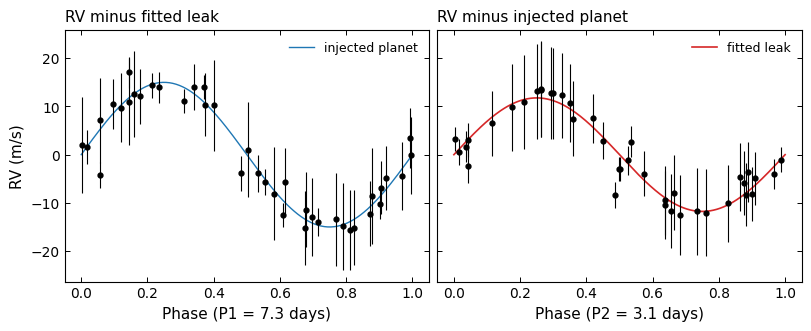

In [6]:
leak = leak_per_w * (w - 0.5)
phase_grid = np.linspace(0, 1, 200)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
plot_points(axs[0], (t / P1) % 1, (obs.vels - leak - offset) * 1e3, obs.evels * 1e3)
plot_extra(axs[0], phase_grid, K1 * 1e3 * np.sin(2 * np.pi * phase_grid), label="injected planet")
axs[0].set_xlabel(f"Phase (P1 = {P1} days)")
axs[0].set_ylabel("RV (m/s)")
axs[0].set_title("RV minus fitted leak", loc="left")
plot_points(axs[1], (t / P2) % 1, (obs.vels - v_planet - offset) * 1e3, obs.evels * 1e3)
plot_model(axs[1], phase_grid, leak_per_w * A_W * 1e3 * np.sin(2 * np.pi * phase_grid),
           label="fitted leak")
axs[1].set_xlabel(f"Phase (P2 = {P2} days)")
axs[1].set_title("RV minus injected planet", loc="left")
for ax in axs:
    ax.legend(loc="upper right")
plt.show()

**The periodograms.** On the same detector: GLS of the RVs, USuRPER of the spectra, and the two
partial periodograms. For comparison we also compute each partial statistic *without* its control.
For shift, that is the plain PDC of the RVs (`calc_pdc`). For shape, it is the PDC of the
rest-frame shape distances, built here from the same public functions the detector uses.

In [7]:
obs.init_periodicity_detector(**GRID)
pd = obs.periodicity_detector
pd.calc_gls()                                   # the RVs
pd.calc_pdc()                                   # the RVs, distance correlation, no control
pd.calc_usurper()                               # the spectra
pd.calc_partial_periodogram("shift")
pd.calc_partial_periodogram("shape")

waves = [s.wv[0] for s in obs.spec_list]
fluxes = [s.sp[0] for s in obs.spec_list]
rest_waves = [dsp.doppler_shift_wave(wv, -v) for wv, v in zip(waves, obs.vels)]
shape_distance = spectral_distance_matrix(rest_waves, fluxes)
shape_plain = pdc_power(t, pd.frequency_grid, unbiased_u_centering(shape_distance, t.size))

def describe(name, freqs, power, local_p=True):
    best = np.argmax(power)
    at = lambda P: power[np.argmin(np.abs(freqs - 1 / P))]
    p_text = f", local p = {pd.calc_pdc_pval([power[best]])[0]:.0e}" if local_p else ""
    print(f"{name:26s} peak at P = {1 / freqs[best]:6.3f} d (power {power[best]:.2f}{p_text}); "
          f"power at P1 {at(P1):+.2f}, at P2 {at(P2):+.2f}")

R = pd.results_power
f = pd.frequency_grid
describe("GLS of the RVs", f, R["GLS"], local_p=False)
describe("USuRPER of the spectra", f, R["USURPER_unbiased"])
describe("PDC of the RVs (no control)", f, R["PDC_unbiased"])
describe("partial: shift", f, R["partial_shift"])
describe("shape, no control", f, shape_plain)
describe("partial: shape", f, R["partial_shape"])

GLS of the RVs             peak at P =  7.220 d (power 0.63); power at P1 +0.60, at P2 +0.37
USuRPER of the spectra     peak at P =  3.106 d (power 0.65, local p = 2e-07); power at P1 -0.02, at P2 +0.65
PDC of the RVs (no control) peak at P =  7.092 d (power 0.40, local p = 3e-05); power at P1 +0.35, at P2 +0.17
partial: shift             peak at P =  7.092 d (power 0.42, local p = 2e-05); power at P1 +0.37, at P2 -0.02
shape, no control          peak at P =  3.106 d (power 0.65, local p = 2e-07); power at P1 -0.03, at P2 +0.65
partial: shape             peak at P =  3.101 d (power 0.64, local p = 3e-07); power at P1 -0.14, at P2 +0.64


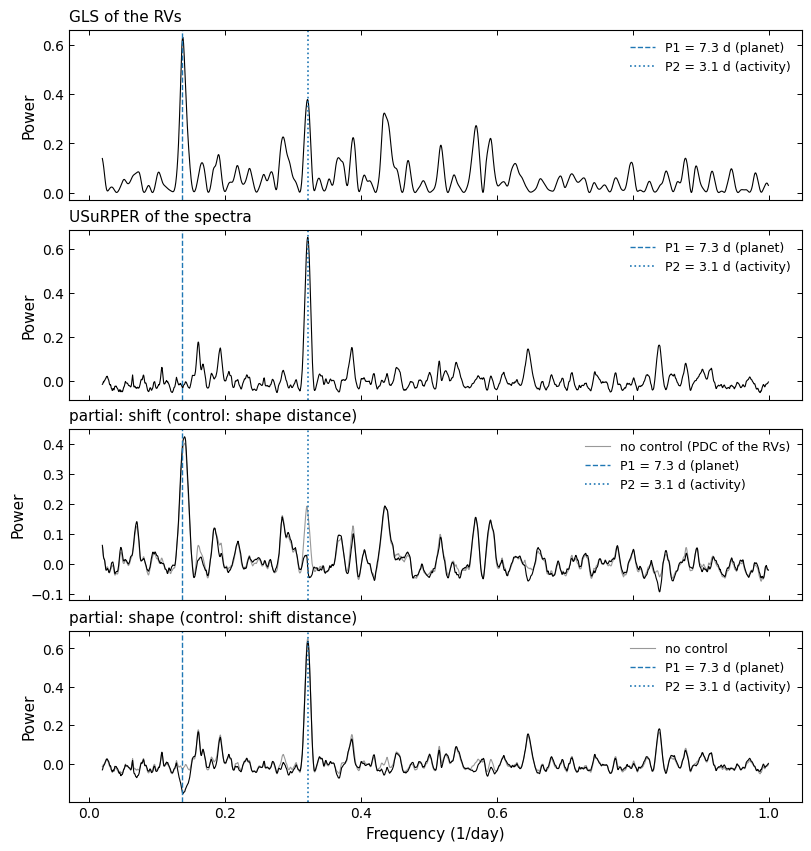

In [8]:
panels = [("GLS", "GLS of the RVs", None),
          ("USURPER_unbiased", "USuRPER of the spectra", None),
          ("partial_shift", "partial: shift (control: shape distance)", (R["PDC_unbiased"], "no control (PDC of the RVs)")),
          ("partial_shape", "partial: shape (control: shift distance)", (shape_plain, "no control"))]
fig, axs = plt.subplots(4, 1, figsize=(8, 8.4), sharex=True)
for ax, (key, title, plain) in zip(axs, panels):
    if plain is not None:
        ax.plot(f, plain[0], color=GREY, lw=0.8, label=plain[1])
    plot_curve(ax, f, R[key], lw=0.8)
    ax.axvline(1 / P1, color=EXTRA_COLOR, ls="--", lw=1, label=f"P1 = {P1} d (planet)")
    ax.axvline(1 / P2, color=EXTRA_COLOR, ls=":", lw=1.2, label=f"P2 = {P2} d (activity)")
    ax.set_ylabel("Power")
    ax.set_title(title, loc="left")
    ax.legend(loc="upper right")
axs[-1].set_xlabel("Frequency (1/day)")
plt.show()

Reading from the top:

- **GLS of the RVs** has peaks at both periods. Nothing in the RVs says the 3.1-day peak is not a
  second planet.
- **USuRPER** sees only $P_2$ (power −0.02 at $P_1$). The temperature change alters the
  spectrum far more than a 15 m/s shift does (notebook 07: some 60 times more than its own
  leak), so at this S/N the planet does not register in the spectra as a whole.
- **Shift**: $P_1$ stands out. The $P_2$ peak of the uncontrolled PDC (grey, 0.17) drops to
  −0.02: the part of the RV distances that follows the shape distances, the leak, has been
  projected out. The highest peak, at 7.09 d rather than 7.3 d, is 0.004/day off, well within a
  peak width of $1/T \approx$ 0.011/day.
- **Shape**: $P_2$ only. Shifting the spectra to rest already removed the planet, so the control
  changes little here (0.65 without it, 0.64 with it, at $P_2$). At $P_1$ the partial power is
  negative (−0.14): the phase distances at $P_1$ follow the RV distances, and once that part is
  projected off, the remainder slightly anti-correlates with the shape distances. It carries no
  detection.

The local p-values are for one frequency, as in notebook 05; section 6 checks them for the
partial statistic.

## 5. Two contrasting stars

The same schedule, noise and template, with one signal at a time: a quiet star with the planet
($w$ fixed at 0.5), and an active star with no planet.

In [9]:
cases = {"planet only": (v_planet, np.full_like(t, 0.5)),
         "activity only": (np.zeros_like(t), w)}
detectors = {}
for name, (v_case, w_case) in cases.items():
    o = observe(v_case, w_case)
    o.calc_rv_against_template(mean_template, dv=0.1, vel_bound=30)
    o.init_periodicity_detector(**GRID)
    d = o.periodicity_detector
    d.calc_gls()
    d.calc_pdc()
    d.calc_partial_periodogram("shift")
    d.calc_partial_periodogram("shape")
    detectors[name] = d
    print(f"{name}: RV rms {np.std(o.vels) * 1e3:.1f} m/s")
    for key in ("GLS", "PDC_unbiased", "partial_shift", "partial_shape"):
        period, power = peak(d, key)
        p_text = "" if key == "GLS" else f", local p = {d.calc_pdc_pval([power])[0]:.0e}"
        print(f"  {key:14s} peak at P = {period:6.3f} d (power {power:.2f}{p_text}); "
              f"power at P1 {power_at(d, key, P1):+.2f}, at P2 {power_at(d, key, P2):+.2f}")

planet only: RV rms 10.6 m/s
  GLS            peak at P =  7.273 d (power 0.95); power at P1 +0.94, at P2 +0.02
  PDC_unbiased   peak at P =  7.246 d (power 0.63, local p = 3e-07); power at P1 +0.62, at P2 -0.02
  partial_shift  peak at P =  7.246 d (power 0.63, local p = 3e-07); power at P1 +0.62, at P2 -0.02
  partial_shape  peak at P =  2.198 d (power 0.09, local p = 3e-02); power at P1 -0.03, at P2 +0.02


activity only: RV rms 8.4 m/s
  GLS            peak at P =  3.110 d (power 0.92); power at P1 +0.01, at P2 +0.91
  PDC_unbiased   peak at P =  3.110 d (power 0.61, local p = 4e-07); power at P1 -0.04, at P2 +0.59
  partial_shift  peak at P =  3.150 d (power 0.22, local p = 2e-03); power at P1 -0.03, at P2 +0.05
  partial_shape  peak at P =  3.086 d (power 0.37, local p = 8e-05); power at P1 +0.02, at P2 +0.33


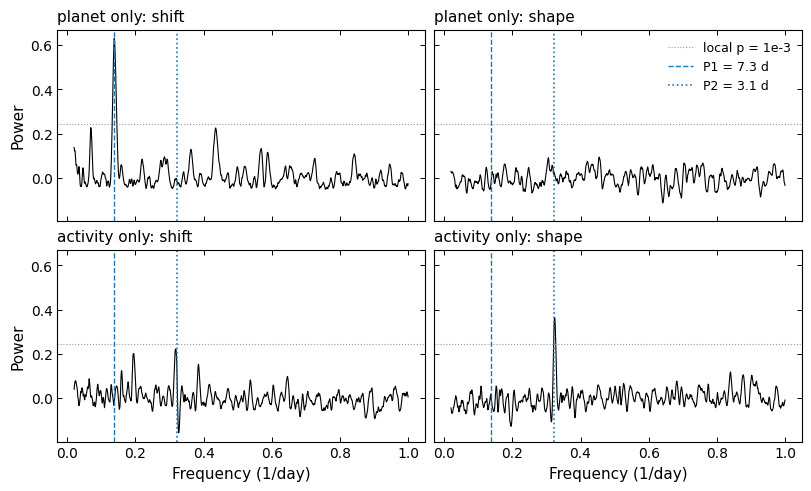

In [10]:
level = pd.calc_pdc_pval([1e-3], inverse_sf=True)[0]
fig, axs = plt.subplots(2, 2, figsize=(8, 4.8), sharex=True, sharey=True)
for row, (name, d) in zip(axs, detectors.items()):
    for ax, key in zip(row, ("partial_shift", "partial_shape")):
        plot_curve(ax, d.results_frequency[key], d.results_power[key], lw=0.8)
        ax.axhline(level, color=GREY, ls=":", lw=0.8, label="local p = 1e-3")
        ax.axvline(1 / P1, color=EXTRA_COLOR, ls="--", lw=1, label=f"P1 = {P1} d")
        ax.axvline(1 / P2, color=EXTRA_COLOR, ls=":", lw=1.2, label=f"P2 = {P2} d")
        ax.set_title(f"{name}: {key.split('_')[1]}", loc="left")
    row[0].set_ylabel("Power")
for ax in axs[-1]:
    ax.set_xlabel("Frequency (1/day)")
axs[0, 1].legend(loc="upper right")
plt.show()

- **Planet only**: the shift periodogram finds $P_1$; the shape periodogram has no significant
  peak, since nothing changes once the spectra are shifted to rest.
- **Activity only**: the RVs are pure leak, so GLS and the plain PDC find 3.1 days, a false
  planet (PDC power 0.61). The shift periodogram drops to a weak bump near $P_2$ (0.22, local
  p = 2e-3), below the 1e-3 level and, with ~85 independent frequencies searched, not
  significant. It is not exactly zero: as in the toy of section 3, the projection removes only
  the part of the leak that is linear in the U-centred shape distances. The shape periodogram
  finds $P_2$, with lower power than in section 4 (0.37 against 0.64). Here the RV distances are
  themselves a function of the shape change (the leak), so the control removes part of the shape
  signal too. The method splits what the two distances do *not* share. When the RVs are nothing
  but the leak, they share a lot.

## 6. Practical notes

**What it needs.** The RVs, measured first (`calc_rv_against_template` stores them in
`time_series.calculated_vrad_list`), and the spectra of one order. As with USuRPER, multi-order
input raises; pick one order with `Observations.select_orders`. The shape distance is computed
on the wavelength range common to all the rest-frame spectra. The caller's spectra are not
modified: the shift to rest is done on copies.

**What it assumes.** That each measured RV is the Doppler shift plus a leak that follows the
shape. The projection removes only the part of the RV distances that is linear in the U-centred
shape distances (section 3), so part of a leak can survive (section 5, activity only: 0.22
against 0.61). A shape change that does not reach the shape distance cannot be controlled for,
for example one outside the chosen order. And a planet whose period equals the activity's cannot
be separated: the two distances would then share the period.

**p-values.** `calc_pdc_pval` uses the $\chi^2_1$ approximation of Shen et al. (2019) for the
unbiased distance correlation. It is *local*, for one trial frequency; the search over the grid
needs a look-elsewhere correction (notebook 05). Shen et al. derived it for the distance
correlation. SPARTA applies the same formula to the partial periodograms (`plot_periodograms`
draws the levels on those panels too), but neither that paper nor the code establishes it for
the partial statistic. A quick check on our data: permute the epochs' times, which destroys any periodicity, and see how
often the partial power at one frequency (0.2/day) exceeds each level.

In [11]:
shift_distance = scalar_distance_matrix(obs.vels)
levels = pd.calc_pdc_pval([0.05, 0.01], inverse_sf=True)
perm = np.random.default_rng(1)
for name, (a, c) in {"shift": (shift_distance, shape_distance),
                     "shape": (shape_distance, shift_distance)}.items():
    A, C = partial_centering(a, c)
    null = np.array([pdc_power(perm.permutation(t), [0.2], A, control=C)[0] for _ in range(4000)])
    print(f"partial {name}: exceeds the p = 0.05 level in {np.mean(null > levels[0]):.3f}, "
          f"the p = 0.01 level in {np.mean(null > levels[1]):.4f} of 4000 permutations")

partial shift: exceeds the p = 0.05 level in 0.045, the p = 0.01 level in 0.0043 of 4000 permutations
partial shape: exceeds the p = 0.05 level in 0.047, the p = 0.01 level in 0.0060 of 4000 permutations


Here the levels hold, slightly conservatively at 0.01. That is one data set at one frequency, not
a proof. Treat partial p-values as a guide, and confirm a candidate with a permutation test like
this one, or by injection and recovery.

**Reading the peaks.** PDC-type periodograms answer "are close phases close in value?", which a
sinusoid also satisfies weakly at *twice* its period. On this schedule, the noiseless planet RVs
alone give:

In [12]:
quiet = Observations(time_series=TimeSeries(times=list(t), vals=list(v_planet)))
quiet.init_periodicity_detector(**GRID)
quiet.periodicity_detector.calc_pdc()
for label, period in ((f"P1 = {P1} d", P1), (f"2 P1 = {2 * P1} d", 2 * P1)):
    print(f"PDC of the noiseless planet RVs at {label:12s}: {power_at(quiet.periodicity_detector, 'PDC_unbiased', period):.2f}")
print(f"planet-only shift periodogram (section 5) at 2 P1: "
      f"{power_at(detectors['planet only'], 'partial_shift', 2 * P1):.2f}")

PDC of the noiseless planet RVs at P1 = 7.3 d  : 0.66
PDC of the noiseless planet RVs at 2 P1 = 14.6 d: 0.24
planet-only shift periodogram (section 5) at 2 P1: 0.22


The shift periodogram inherits this sub-harmonic: it is the peak near 0.07/day in the planet-only
shift panel of section 5. Its size depends on the sampling, and on other schedules it can rival
the true peak. Check $P$ against $2P$ (a fold, or GLS) before believing a
long period.

## Summary

- **The problem.** Line-shape changes leak into the RVs at their own period (here 11 m/s at
  3.1 d). The GLS of the RVs found both the 7.3-day planet and the 3.1-day activity, and with no
  planet it found the activity alone, a false planet.
- **The idea.** Partial distance correlation removes from two U-centred distance matrices their
  projection on a third, then correlates the rest (toy: dCor 0.91 dropped to pdCor 0.05 when
  the only link was the control, but stayed at 0.73 for a direct link).
- **The periodograms** (`calc_partial_periodogram`). *Shift*: RV distances against phase,
  controlling for the rest-frame spectral (shape) distances. It found the planet, and the
  activity's RV peak dropped from 0.17 to −0.02; with no planet, a weak residue (0.22, not
  significant) was left of the leak's 0.61. *Shape*: shape distances against phase, controlling
  for the RV distances. It found the activity, without the planet.
- **Needs and limits.** RVs plus one order of spectra; the leak is removed only as far as it is
  linear in the U-centred distances; equal periods cannot be split; the p-values are local and
  borrowed from the distance correlation (they held in a permutation check here).

**See also:** notebook 05 for the periodograms and their p-values, 07 for USuRPER and the leak
itself, 02 for the RVs (UNICOR) the partial periodograms start from.